# Tarea 3 — PyTorch

**Nombre del integrante:**Alexander Ramirez

**Cédula del integrante:**29611077

Este notebook implementa un clasificador de **Fashion MNIST** con PyTorch y permite:

- Crear una red nueva o cargar una red previamente guardada.
- Elegir clasificación original de 10 clases o clasificación simplificada de 4 clases.
- Crear arquitectura rectangular o la arquitectura llamada *convolutional* en el enunciado.
- Entrenar por cualquier número de épocas y continuar entrenando después.
- Probar contra el conjunto de prueba.
- Mostrar *accuracy*, *precision*, *recall* y matriz de confusión.
- Guardar/cargar redes `.pth` con el contrato definido en el `README.md` del repositorio.
- Configurar optimizaciones.
- Generar opcionalmente las cuatro redes requeridas para la entrega.

> **Importante:** antes del commit ejecuta **Kernel → Restart & Run All**.  
> La última celda debe quedar esperando una opción del menú sin producir errores.


## 1. Imports y constantes

Aquí se centralizan las constantes de la tarea.

La entrada siempre tiene **784 valores** porque una imagen Fashion MNIST tiene `28 × 28 = 784` píxeles.

Para las clases simplificadas se usa exactamente este orden:

- `0 = Top`
- `1 = Bottom`
- `2 = Footwear`
- `3 = Bag`

El programa detecta automáticamente CPU, CUDA o Apple Silicon/MPS.


In [1]:
from pathlib import Path
import copy

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms

# Reproducibility helps us compare experiments using the same starting conditions.
SEED = 26271
torch.manual_seed(SEED)

NOTEBOOK_ID = 1
INPUT_SIZE = 28 * 28
DEFAULT_HIDDEN_LAYERS = 2
DEFAULT_RECTANGULAR_NEURONS = 512
DEFAULT_BATCH_SIZE = 128
VALIDATION_SIZE = 6000

DATA_DIR = Path("./data")

ORIGINAL_CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

SIMPLIFIED_CLASS_NAMES = ["Top", "Bottom", "Footwear", "Bag"]

CLASS_NAMES = {
    "original": ORIGINAL_CLASS_NAMES,
    "simplified": SIMPLIFIED_CLASS_NAMES,
}

# Fashion MNIST original label -> simplified label.
# 0 T-shirt -> Top
# 1 Trouser -> Bottom
# 2 Pullover -> Top
# 3 Dress -> Bottom
# 4 Coat -> Top
# 5 Sandal -> Footwear
# 6 Shirt -> Top
# 7 Sneaker -> Footwear
# 8 Bag -> Bag
# 9 Ankle boot -> Footwear
SIMPLIFIED_MAP = (0, 1, 0, 1, 0, 2, 0, 2, 3, 2)

DEFAULT_OPTIMIZATIONS = {
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "batch_norm": False,
    "early_stopping": False,
    "patience": 3,
}

# Select the best available device, while keeping checkpoints portable.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Device: {DEVICE}")


Device: mps


## 2. Datos — Fashion MNIST original y clases simplificadas

`torchvision.datasets.FashionMNIST` descarga el conjunto de entrenamiento y el conjunto de prueba dentro de `./data`.

Solo se aplica `transforms.ToTensor()`, por lo que cada píxel queda en el rango `[0, 1]`.

La clase `SimplifiedFashionDataset` **no modifica** Fashion MNIST. Solamente traduce la etiqueta original a una de las cuatro clases simplificadas al momento de leer cada ejemplo.

Cuando se habilita *early stopping*, se separan 6.000 imágenes del conjunto de entrenamiento para validación. El conjunto oficial de prueba permanece intacto.


In [2]:
class SimplifiedFashionDataset(Dataset):
    """Dataset view that remaps the 10 Fashion MNIST labels into 4 simplified labels."""

    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, original_label = self.base_dataset[index]
        simplified_label = SIMPLIFIED_MAP[int(original_label)]
        return image, simplified_label


_DATASET_CACHE = {}


def get_datasets(classification):
    """Return train and test datasets for original or simplified classification."""
    if classification not in CLASS_NAMES:
        raise ValueError("classification must be 'original' or 'simplified'")

    if classification in _DATASET_CACHE:
        return _DATASET_CACHE[classification]

    transform = transforms.ToTensor()

    base_train = datasets.FashionMNIST(
        root=DATA_DIR,
        train=True,
        download=True,
        transform=transform,
    )
    base_test = datasets.FashionMNIST(
        root=DATA_DIR,
        train=False,
        download=True,
        transform=transform,
    )

    if classification == "simplified":
        train_dataset = SimplifiedFashionDataset(base_train)
        test_dataset = SimplifiedFashionDataset(base_test)
    else:
        train_dataset = base_train
        test_dataset = base_test

    _DATASET_CACHE[classification] = (train_dataset, test_dataset)
    return train_dataset, test_dataset


def make_loaders(classification, batch_size=DEFAULT_BATCH_SIZE, use_validation=False):
    """Create DataLoaders and optionally reserve a validation split for early stopping."""
    train_dataset, test_dataset = get_datasets(classification)

    validation_loader = None

    if use_validation:
        train_size = len(train_dataset) - VALIDATION_SIZE
        generator = torch.Generator().manual_seed(SEED)
        training_part, validation_part = random_split(
            train_dataset,
            [train_size, VALIDATION_SIZE],
            generator=generator,
        )
    else:
        training_part = train_dataset
        validation_part = None

    train_loader = DataLoader(
        training_part,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=(DEVICE.type == "cuda"),
    )

    if validation_part is not None:
        validation_loader = DataLoader(
            validation_part,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(DEVICE.type == "cuda"),
        )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda"),
    )

    return train_loader, validation_loader, test_loader


## 3. Modelos — rectangular y “convolutional”

### Red rectangular

Todas las capas ocultas tienen el mismo número de neuronas.

Con los valores por defecto:

```text
784 → 512 → 512 → 10
```

### Red “convolutional” del enunciado

En esta tarea el término **convolutional no significa `Conv2d`**. El `README.md` del repo exige un `nn.Sequential` formado por `Flatten`, `Linear`, `ReLU`, `BatchNorm1d` y `Dropout`.

Por eso se implementa como una red densa en forma de embudo: el tamaño de cada capa oculta se obtiene por interpolación lineal entre 784 y el número de salidas.

Para `L` capas ocultas:

\[
n_i = round\left(784 + (n_{out}-784)\frac{i}{L+1}\right)
\]

Con 2 capas ocultas y 10 salidas:

```text
784 → 526 → 268 → 10
```

> El PDF muestra `258` en su figura, pero la interpolación lineal indicada en el texto produce `268`. Este notebook sigue la fórmula de interpolación y el contrato del repo.

Cada modelo termina en una capa `Linear` **sin Softmax**, porque `nn.CrossEntropyLoss()` espera directamente los *logits*.


In [3]:
def calculate_hidden_sizes(network_type, hidden_layers, rectangular_neurons, output_size):
    """Return the number of neurons in every hidden layer."""
    if hidden_layers < 0:
        raise ValueError("hidden_layers cannot be negative")

    if network_type == "rectangular":
        if rectangular_neurons is None or rectangular_neurons < 1:
            raise ValueError("rectangular_neurons must be at least 1")
        return [rectangular_neurons] * hidden_layers

    if network_type == "convolutional":
        return [
            round(INPUT_SIZE + (output_size - INPUT_SIZE) * i / (hidden_layers + 1))
            for i in range(1, hidden_layers + 1)
        ]

    raise ValueError("network_type must be 'rectangular' or 'convolutional'")


def build_model(hidden_sizes, output_size, batch_norm=False, dropout=0.0):
    """Build the grader-compatible nn.Sequential model."""
    if not 0.0 <= dropout < 1.0:
        raise ValueError("dropout must be in [0, 1)")

    layers = [nn.Flatten()]
    previous_size = INPUT_SIZE

    for hidden_size in hidden_sizes:
        layers.append(nn.Linear(previous_size, hidden_size))

        if batch_norm:
            layers.append(nn.BatchNorm1d(hidden_size))

        layers.append(nn.ReLU())

        if dropout > 0:
            layers.append(nn.Dropout(dropout))

        previous_size = hidden_size

    layers.append(nn.Linear(previous_size, output_size))
    return nn.Sequential(*layers)


def create_network(
    classification="original",
    network_type="rectangular",
    hidden_layers=DEFAULT_HIDDEN_LAYERS,
    rectangular_neurons=DEFAULT_RECTANGULAR_NEURONS,
    optimizations=None,
):
    """Create a complete network package used by the menu."""
    if classification not in CLASS_NAMES:
        raise ValueError("invalid classification")

    if optimizations is None:
        optimizations = copy.deepcopy(DEFAULT_OPTIMIZATIONS)
    else:
        optimizations = copy.deepcopy(optimizations)

    output_size = len(CLASS_NAMES[classification])

    hidden_sizes = calculate_hidden_sizes(
        network_type=network_type,
        hidden_layers=hidden_layers,
        rectangular_neurons=rectangular_neurons,
        output_size=output_size,
    )

    model = build_model(
        hidden_sizes=hidden_sizes,
        output_size=output_size,
        batch_norm=optimizations["batch_norm"],
        dropout=optimizations["dropout"],
    ).to(DEVICE)

    hyperparameters = {
        "network_type": network_type,
        "hidden_layers": hidden_layers,
        "neurons_per_layer": hidden_sizes,
        "rectangular_neurons": rectangular_neurons if network_type == "rectangular" else None,
        "epochs": 0,
        "classification": classification,
        "output_size": output_size,
        "optimizations": optimizations,
    }

    return {
        "model": model,
        "hyperparameters": hyperparameters,
        "loss_history": [],
    }


def describe_network(network):
    """Print a short human-readable description of the current network."""
    hp = network["hyperparameters"]
    opts = hp["optimizations"]

    print("\n--- Red actual ---")
    print(f"Clasificación: {hp['classification']} ({hp['output_size']} clases)")
    print(f"Tipo: {hp['network_type']}")
    print(f"Arquitectura: {INPUT_SIZE} -> {hp['neurons_per_layer']} -> {hp['output_size']}")
    print(f"Épocas acumuladas: {hp['epochs']}")
    print(f"Optimizador: {opts['optimizer']}")
    print(f"Learning rate: {opts['learning_rate']}")
    print(f"Weight decay: {opts['weight_decay']}")
    print(f"Batch normalization: {'sí' if opts['batch_norm'] else 'no'}")
    print(f"Dropout: {opts['dropout']}")
    print(
        "Early stopping: "
        + (f"sí (paciencia={opts['patience']})" if opts["early_stopping"] else "no")
    )


## 4. Entrenar, probar, guardar y cargar

### Entrenamiento

El ciclo de entrenamiento realiza, por cada *batch*:

```text
imágenes
   ↓
forward pass
   ↓
logits
   ↓
CrossEntropyLoss
   ↓
backward()
   ↓
gradientes
   ↓
optimizer.step()
   ↓
pesos actualizados
```

Después de cada época se almacena la pérdida promedio y se muestra un gráfico.

### Evaluación

La prueba usa **únicamente el conjunto oficial de test** y calcula:

- `accuracy`
- `precision` por clase y macro-promedio
- `recall` por clase y macro-promedio
- matriz de confusión

### Checkpoint `.pth`

El archivo se guarda con:

```python
{
    "state_dict": model.state_dict(),
    "hyperparameters": {...}
}
```

Los pesos se convierten a CPU antes de guardarlos para que el archivo pueda abrirse también en una máquina sin GPU/MPS.


In [4]:
def make_optimizer(network):
    """Create an optimizer using the current training options."""
    hp = network["hyperparameters"]
    opts = hp["optimizations"]
    parameters = network["model"].parameters()

    name = opts["optimizer"]
    learning_rate = opts["learning_rate"]
    weight_decay = opts["weight_decay"]

    if name == "SGD":
        return torch.optim.SGD(
            parameters,
            lr=learning_rate,
            momentum=0.9,
            weight_decay=weight_decay,
        )

    if name == "Adam":
        return torch.optim.Adam(
            parameters,
            lr=learning_rate,
            weight_decay=weight_decay,
        )

    if name == "AdamW":
        return torch.optim.AdamW(
            parameters,
            lr=learning_rate,
            weight_decay=weight_decay,
        )

    raise ValueError(f"unsupported optimizer: {name}")


def average_loss(model, data_loader, loss_function):
    """Compute average loss without modifying the model."""
    model.eval()
    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = loss_function(logits, labels)

            total_loss += loss.item() * labels.size(0)
            total_examples += labels.size(0)

    return total_loss / max(total_examples, 1)


def train_network(network, epochs):
    """Train for additional epochs and plot the loss of this training session."""
    if epochs < 1:
        raise ValueError("epochs must be at least 1")

    model = network["model"]
    hp = network["hyperparameters"]
    opts = hp["optimizations"]

    train_loader, validation_loader, _ = make_loaders(
        classification=hp["classification"],
        use_validation=opts["early_stopping"],
    )

    optimizer = make_optimizer(network)
    loss_function = nn.CrossEntropyLoss()

    session_losses = []
    session_epoch_numbers = []

    best_validation_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    for _ in range(epochs):
        model.train()
        running_loss = 0.0
        example_count = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(images)
            loss = loss_function(logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            example_count += labels.size(0)

        epoch_loss = running_loss / example_count

        hp["epochs"] += 1
        network["loss_history"].append(epoch_loss)
        session_losses.append(epoch_loss)
        session_epoch_numbers.append(hp["epochs"])

        print(f"Epoch {hp['epochs']} - train_loss={epoch_loss:.5f}")

        if validation_loader is not None:
            validation_loss = average_loss(model, validation_loader, loss_function)
            print(f"Epoch {hp['epochs']} - validation_loss={validation_loss:.5f}")

            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                epochs_without_improvement = 0

                # Keep the best state on CPU so it does not depend on the current accelerator.
                best_state = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }
            else:
                epochs_without_improvement += 1

                if epochs_without_improvement >= opts["patience"]:
                    print("Early stopping triggered.")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
        model.to(DEVICE)

    plt.figure(figsize=(8, 4))
    plt.plot(session_epoch_numbers, session_losses, marker="o")
    plt.xlabel("Época")
    plt.ylabel("Pérdida (loss)")
    plt.title("Pérdida por época")
    plt.grid(alpha=0.25)
    plt.show()

    return session_losses


def compute_confusion_matrix(network):
    """Return the confusion matrix on the official Fashion MNIST test set."""
    model = network["model"]
    hp = network["hyperparameters"]

    _, _, test_loader = make_loaders(
        classification=hp["classification"],
        use_validation=False,
    )

    class_count = hp["output_size"]
    matrix = torch.zeros((class_count, class_count), dtype=torch.int64)

    model.eval()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            predictions = model(images).argmax(dim=1)

            flat_indexes = (labels * class_count + predictions).detach().cpu()
            batch_matrix = torch.bincount(
                flat_indexes,
                minlength=class_count * class_count,
            ).reshape(class_count, class_count)

            matrix += batch_matrix

    return matrix


def metrics_from_confusion_matrix(matrix):
    """Compute accuracy, per-class precision/recall, and macro averages."""
    matrix_float = matrix.float()

    true_positives = torch.diag(matrix_float)
    predicted_totals = matrix_float.sum(dim=0)
    real_totals = matrix_float.sum(dim=1)

    precision = true_positives / predicted_totals.clamp_min(1)
    recall = true_positives / real_totals.clamp_min(1)

    accuracy = true_positives.sum() / matrix_float.sum().clamp_min(1)

    return {
        "accuracy": accuracy.item(),
        "precision": precision,
        "recall": recall,
        "macro_precision": precision.mean().item(),
        "macro_recall": recall.mean().item(),
    }


def plot_confusion_matrix(matrix, class_names):
    """Display the confusion matrix using matplotlib."""
    matrix_values = matrix.numpy()

    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix_values)
    fig.colorbar(image, ax=ax)

    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title("Matriz de confusión")

    maximum = matrix_values.max() if matrix_values.size else 0

    for row in range(len(class_names)):
        for column in range(len(class_names)):
            value = matrix_values[row, column]
            ax.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
            )

    plt.tight_layout()
    plt.show()


def evaluate_network(network, show_plot=True):
    """Evaluate the network and print the requested metrics."""
    hp = network["hyperparameters"]
    names = CLASS_NAMES[hp["classification"]]

    matrix = compute_confusion_matrix(network)
    metrics = metrics_from_confusion_matrix(matrix)

    print("\n=== Resultados de prueba ===")
    print(f"Accuracy:        {metrics['accuracy'] * 100:.2f}%")
    print(f"Macro precision: {metrics['macro_precision'] * 100:.2f}%")
    print(f"Macro recall:    {metrics['macro_recall'] * 100:.2f}%")

    print("\nPor clase:")
    print(f"{'Clase':<16}{'Precision':>12}{'Recall':>12}")

    for index, name in enumerate(names):
        precision = metrics["precision"][index].item() * 100
        recall = metrics["recall"][index].item() * 100
        print(f"{name:<16}{precision:>11.2f}%{recall:>11.2f}%")

    if show_plot:
        plot_confusion_matrix(matrix, names)

    return metrics, matrix


def default_checkpoint_name(network):
    """Return the exact filename expected for notebook 1."""
    hp = network["hyperparameters"]

    return (
        f"pytorch_fashion_{NOTEBOOK_ID}_"
        f"{hp['classification']}_{hp['network_type']}.pth"
    )


def save_network(network, path=None):
    """Save a portable checkpoint using the repository contract."""
    if path is None:
        path = default_checkpoint_name(network)

    path = Path(path)

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value in network["model"].state_dict().items()
    }

    checkpoint = {
        "state_dict": cpu_state_dict,
        "hyperparameters": copy.deepcopy(network["hyperparameters"]),
    }

    torch.save(checkpoint, path)
    print(f"Checkpoint saved: {path}")

    return path


def load_network(path):
    """Load one of this notebook's checkpoints and rebuild its architecture."""
    path = Path(path)

    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        # Compatibility with older PyTorch versions that do not support weights_only.
        checkpoint = torch.load(path, map_location="cpu")

    if "state_dict" not in checkpoint or "hyperparameters" not in checkpoint:
        raise ValueError("invalid checkpoint format")

    hp = checkpoint["hyperparameters"]
    opts = hp["optimizations"]

    hidden_sizes = hp.get("neurons_per_layer")
    if hidden_sizes is None:
        raise ValueError("checkpoint does not contain neurons_per_layer")

    output_size = hp.get("output_size", len(CLASS_NAMES[hp["classification"]]))

    model = build_model(
        hidden_sizes=hidden_sizes,
        output_size=output_size,
        batch_norm=opts.get("batch_norm", False),
        dropout=opts.get("dropout", 0.0),
    )

    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE)

    hp["output_size"] = output_size

    return {
        "model": model,
        "hyperparameters": hp,
        "loss_history": [],
    }


def recommended_delivery_configurations():
    """Return practical starting configurations for the four required checkpoints."""
    base_options = copy.deepcopy(DEFAULT_OPTIMIZATIONS)
    base_options.update(
        {
            "optimizer": "Adam",
            "learning_rate": 0.001,
            "weight_decay": 0.0001,
            "dropout": 0.10,
            "batch_norm": True,
            "early_stopping": False,
            "patience": 3,
        }
    )

    return [
        {
            "classification": "original",
            "network_type": "rectangular",
            "hidden_layers": 2,
            "rectangular_neurons": 512,
            "epochs": 8,
            "optimizations": copy.deepcopy(base_options),
        },
        {
            "classification": "original",
            "network_type": "convolutional",
            "hidden_layers": 2,
            "rectangular_neurons": 512,
            "epochs": 8,
            "optimizations": copy.deepcopy(base_options),
        },
        {
            "classification": "simplified",
            "network_type": "rectangular",
            "hidden_layers": 2,
            "rectangular_neurons": 256,
            "epochs": 6,
            "optimizations": copy.deepcopy(base_options),
        },
        {
            "classification": "simplified",
            "network_type": "convolutional",
            "hidden_layers": 2,
            "rectangular_neurons": 512,
            "epochs": 6,
            "optimizations": copy.deepcopy(base_options),
        },
    ]


def train_and_save_delivery_models():
    """Optional helper that trains, evaluates and saves all four required networks."""
    results = []

    for config in recommended_delivery_configurations():
        print("\n" + "=" * 72)
        print(
            "Training delivery model: "
            f"{config['classification']} / {config['network_type']}"
        )

        network = create_network(
            classification=config["classification"],
            network_type=config["network_type"],
            hidden_layers=config["hidden_layers"],
            rectangular_neurons=config["rectangular_neurons"],
            optimizations=config["optimizations"],
        )

        describe_network(network)
        train_network(network, config["epochs"])
        metrics, _ = evaluate_network(network, show_plot=True)
        path = save_network(network)

        results.append(
            {
                "path": str(path),
                "accuracy": metrics["accuracy"],
                "network": network,
            }
        )

    print("\n=== Resumen de las cuatro redes ===")
    for item in results:
        print(f"{item['path']}: accuracy={item['accuracy'] * 100:.2f}%")

    return results


## 5. Menú interactivo

El menú permite cumplir el flujo pedido por el enunciado:

```text
crear/cargar
    ↓
entrenar
    ↓
probar
    ↓
guardar
    ↓
volver al menú
```

Las opciones de `dropout` y `batch normalization` forman parte de la arquitectura, por lo que se eligen al crear una red.

El optimizador, *learning rate*, *weight decay* y *early stopping* pueden ajustarse después desde **Configurar entrenamiento**.

La opción **Generar las 4 redes de entrega** es un atajo opcional. Entrena una configuración inicial razonable para cada combinación y guarda automáticamente los nombres exigidos. Después debes revisar el *accuracy*; si una red queda por debajo del objetivo, puedes cargarla y continuar entrenando.


In [ ]:
def ask_integer(prompt, default=None, minimum=None):
    """Read an integer from the user, repeating until it is valid."""
    while True:
        raw = input(prompt).strip()

        if raw == "" and default is not None:
            return default

        try:
            value = int(raw)
        except ValueError:
            print("Ingresa un número entero.")
            continue

        if minimum is not None and value < minimum:
            print(f"El valor mínimo es {minimum}.")
            continue

        return value


def ask_float(prompt, default=None, minimum=None, maximum=None):
    """Read a float from the user, repeating until it is valid."""
    while True:
        raw = input(prompt).strip()

        if raw == "" and default is not None:
            return default

        try:
            value = float(raw)
        except ValueError:
            print("Ingresa un número válido.")
            continue

        if minimum is not None and value < minimum:
            print(f"El valor mínimo es {minimum}.")
            continue

        if maximum is not None and value > maximum:
            print(f"El valor máximo es {maximum}.")
            continue

        return value


def ask_yes_no(prompt, default=False):
    """Read a yes/no response."""
    suffix = " [S/n]: " if default else " [s/N]: "
    raw = input(prompt + suffix).strip().lower()

    if raw == "":
        return default

    return raw in ("s", "si", "sí", "y", "yes")


def ask_choice(prompt, options, default_key):
    """Read one key from a dictionary such as {'1': 'original'}."""
    while True:
        raw = input(prompt).strip() or default_key

        if raw in options:
            return options[raw]

        print("Opción inválida.")


def configure_new_network():
    """Interactive builder for a new network."""
    print("\n=== Crear nueva red ===")
    print("Presiona Enter para aceptar el valor por defecto.\n")

    classification = ask_choice(
        "Clasificación: 1) original (10)  2) simplificada (4) [1]: ",
        {"1": "original", "2": "simplified"},
        "1",
    )

    network_type = ask_choice(
        "Tipo: 1) rectangular  2) convolutional/embudo [1]: ",
        {"1": "rectangular", "2": "convolutional"},
        "1",
    )

    hidden_layers = ask_integer(
        f"Número de capas ocultas [{DEFAULT_HIDDEN_LAYERS}]: ",
        default=DEFAULT_HIDDEN_LAYERS,
        minimum=0,
    )

    rectangular_neurons = DEFAULT_RECTANGULAR_NEURONS

    if network_type == "rectangular" and hidden_layers > 0:
        rectangular_neurons = ask_integer(
            f"Neuronas por capa [{DEFAULT_RECTANGULAR_NEURONS}]: ",
            default=DEFAULT_RECTANGULAR_NEURONS,
            minimum=1,
        )

    options = copy.deepcopy(DEFAULT_OPTIMIZATIONS)

    if ask_yes_no("¿Configurar optimizaciones de arquitectura?", default=False):
        options["batch_norm"] = ask_yes_no(
            "¿Usar batch normalization?",
            default=False,
        )
        options["dropout"] = ask_float(
            "Dropout [0.0]: ",
            default=0.0,
            minimum=0.0,
            maximum=0.9,
        )

    if ask_yes_no("¿Configurar entrenamiento ahora?", default=False):
        options["optimizer"] = ask_choice(
            "Optimizador: 1) Adam  2) AdamW  3) SGD [1]: ",
            {"1": "Adam", "2": "AdamW", "3": "SGD"},
            "1",
        )
        options["learning_rate"] = ask_float(
            "Learning rate [0.001]: ",
            default=0.001,
            minimum=0.000001,
        )
        options["weight_decay"] = ask_float(
            "Weight decay [0.0]: ",
            default=0.0,
            minimum=0.0,
        )
        options["early_stopping"] = ask_yes_no(
            "¿Usar early stopping?",
            default=False,
        )
        if options["early_stopping"]:
            options["patience"] = ask_integer(
                "Paciencia en épocas [3]: ",
                default=3,
                minimum=1,
            )

    network = create_network(
        classification=classification,
        network_type=network_type,
        hidden_layers=hidden_layers,
        rectangular_neurons=rectangular_neurons,
        optimizations=options,
    )

    describe_network(network)
    return network


def configure_training_options(network):
    """Change optimization settings that do not alter the architecture."""
    opts = network["hyperparameters"]["optimizations"]

    while True:
        print("\n=== Configurar entrenamiento ===")
        print(f"1) Optimizador        : {opts['optimizer']}")
        print(f"2) Learning rate      : {opts['learning_rate']}")
        print(f"3) Weight decay       : {opts['weight_decay']}")
        print(f"4) Early stopping     : {opts['early_stopping']}")
        print(f"5) Paciencia          : {opts['patience']}")
        print("6) Volver")

        choice = input("Opción: ").strip()

        if choice == "1":
            opts["optimizer"] = ask_choice(
                "1) Adam  2) AdamW  3) SGD [1]: ",
                {"1": "Adam", "2": "AdamW", "3": "SGD"},
                "1",
            )
        elif choice == "2":
            opts["learning_rate"] = ask_float(
                "Nuevo learning rate: ",
                minimum=0.000001,
            )
        elif choice == "3":
            opts["weight_decay"] = ask_float(
                "Nuevo weight decay: ",
                minimum=0.0,
            )
        elif choice == "4":
            opts["early_stopping"] = ask_yes_no(
                "¿Activar early stopping?",
                default=opts["early_stopping"],
            )
        elif choice == "5":
            opts["patience"] = ask_integer(
                "Nueva paciencia: ",
                minimum=1,
            )
        elif choice == "6":
            return
        else:
            print("Opción inválida.")



TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Opción inválida.

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir

=== Crear nueva red ===
Presiona Enter para aceptar el valor por defecto.


--- Red actual ---
Clasificación: original (10 clases)
Tipo: rectangular
Arquitectura: 784 -> [512, 512] -> 10
Épocas acumuladas: 0
Optimizador: Adam
Learning rate: 0.001
Weight decay: 0.0
Batch normalization: sí
Dropout: 0.0
Early stopping: no

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) 

100.0%
100.0%
100.0%
100.0%



=== Resultados de prueba ===
Accuracy:        6.64%
Macro precision: 7.86%
Macro recall:    6.64%

Por clase:
Clase              Precision      Recall
T-shirt/top            4.88%       0.20%
Trouser                0.00%       0.00%
Pullover               0.00%       0.00%
Dress                  0.00%       0.00%
Coat                   2.35%       8.20%
Sandal                13.64%       2.10%
Shirt                 11.64%      48.80%
Sneaker                0.06%       0.10%
Bag                   33.33%       0.10%
Ankle boot            12.66%       6.90%


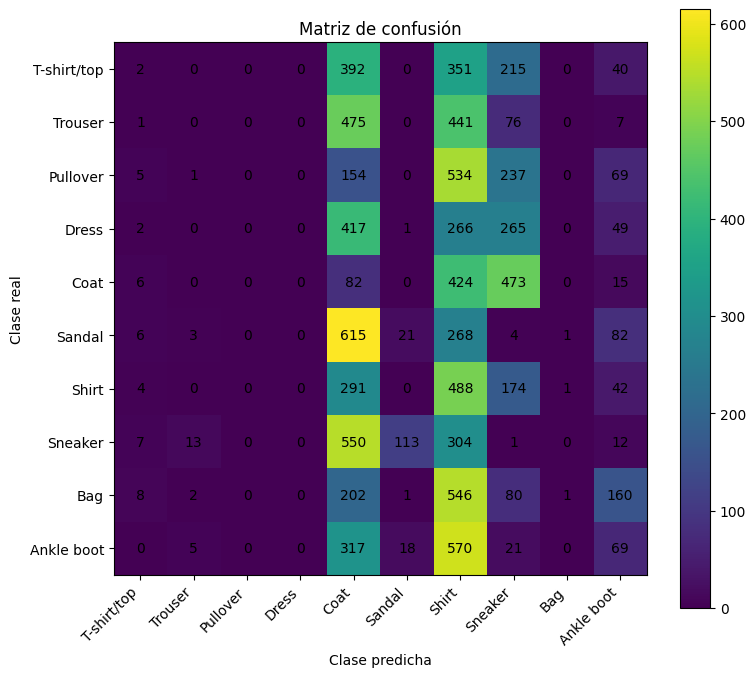


TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir

--- Red actual ---
Clasificación: original (10 clases)
Tipo: rectangular
Arquitectura: 784 -> [512, 512] -> 10
Épocas acumuladas: 0
Optimizador: Adam
Learning rate: 0.001
Weight decay: 0.0
Batch normalization: sí
Dropout: 0.0
Early stopping: no

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Epoch 1 - train_loss=0.41942
Epoch 2 - train_loss=0.32179
Epoch 3 - train_loss=0.28391
Epoch 4 - train_loss=0.25917
Epoch 5 - train_loss=0.23679


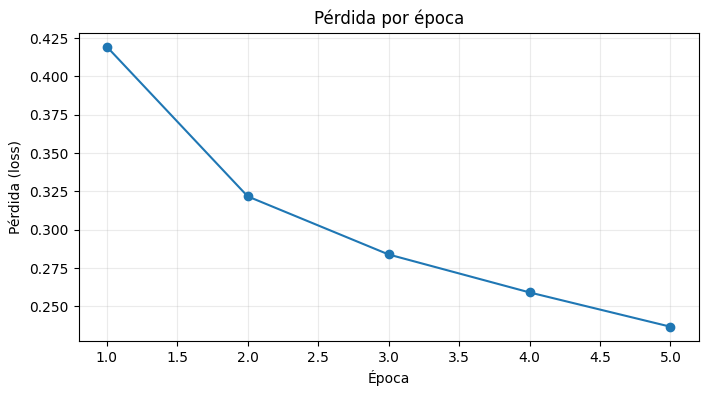


TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir

=== Resultados de prueba ===
Accuracy:        88.03%
Macro precision: 88.07%
Macro recall:    88.03%

Por clase:
Clase              Precision      Recall
T-shirt/top           79.19%      89.80%
Trouser               95.25%      98.20%
Pullover              82.71%      79.40%
Dress                 86.88%      89.40%
Coat                  75.33%      85.80%
Sandal                96.13%      97.00%
Shirt                 79.69%      56.50%
Sneaker               96.38%      90.40%
Bag                   97.58%      96.60%
Ankle boot            91.61%      97.20%


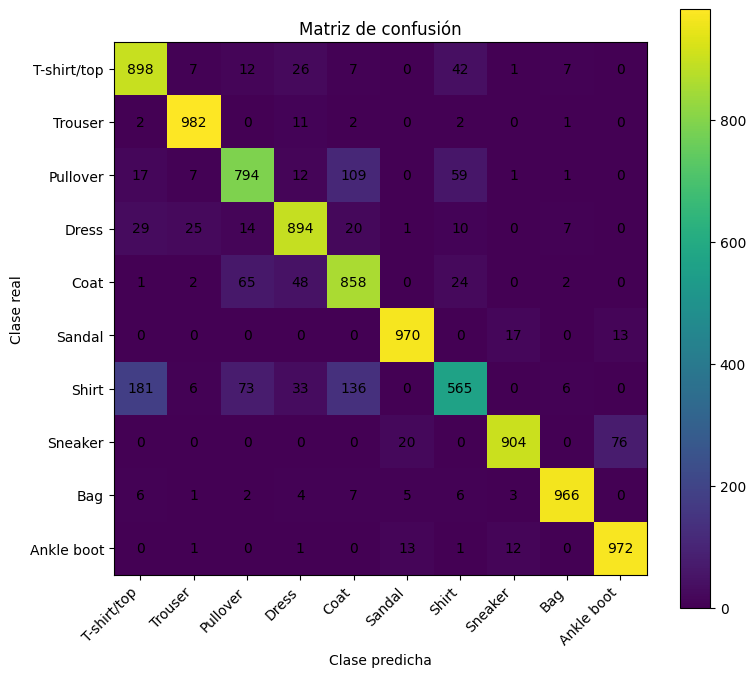


TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Opción inválida.

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Opción inválida.

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Opción inválida.

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red a

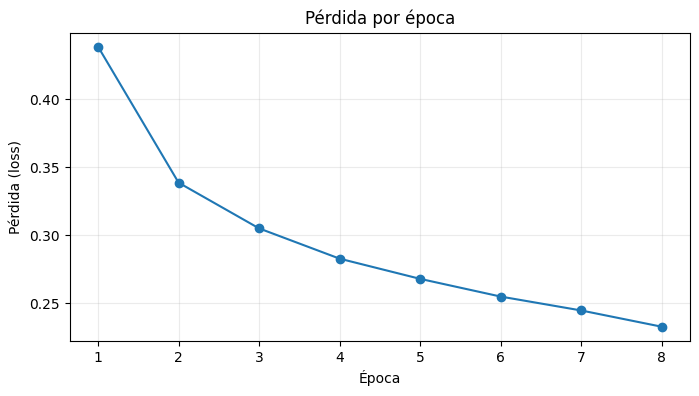


=== Resultados de prueba ===
Accuracy:        87.23%
Macro precision: 87.89%
Macro recall:    87.23%

Por clase:
Clase              Precision      Recall
T-shirt/top           83.61%      84.70%
Trouser               99.69%      96.70%
Pullover              71.73%      86.00%
Dress                 84.07%      91.80%
Coat                  73.10%      87.50%
Sandal                96.45%      95.10%
Shirt                 86.31%      45.40%
Sneaker               95.98%      90.80%
Bag                   97.18%      96.40%
Ankle boot            90.73%      97.90%


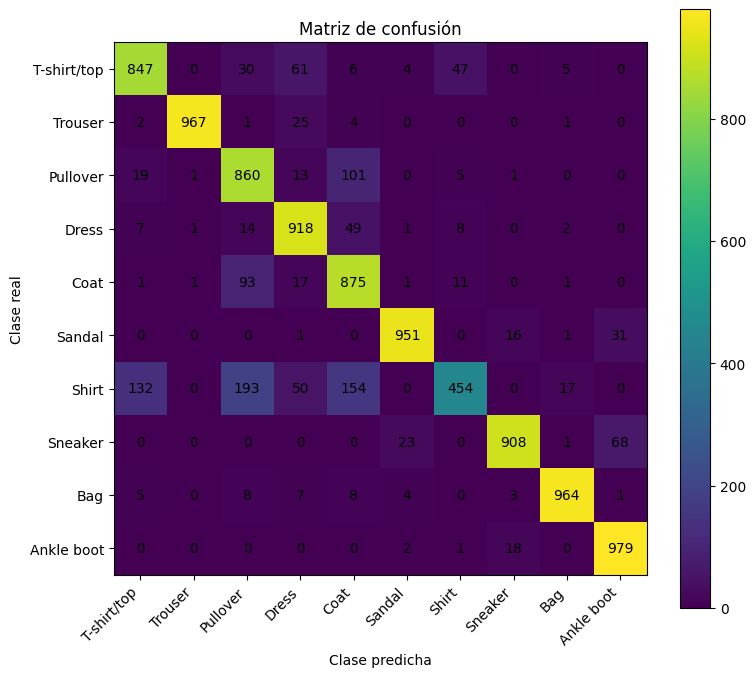

Checkpoint saved: pytorch_fashion_1_original_rectangular.pth

Training delivery model: original / convolutional

--- Red actual ---
Clasificación: original (10 clases)
Tipo: convolutional
Arquitectura: 784 -> [526, 268] -> 10
Épocas acumuladas: 0
Optimizador: Adam
Learning rate: 0.001
Weight decay: 0.0001
Batch normalization: sí
Dropout: 0.1
Early stopping: no
Epoch 1 - train_loss=0.44388
Epoch 2 - train_loss=0.33942
Epoch 3 - train_loss=0.30668
Epoch 4 - train_loss=0.28657
Epoch 5 - train_loss=0.26894
Epoch 6 - train_loss=0.25543
Epoch 7 - train_loss=0.24432
Epoch 8 - train_loss=0.23409


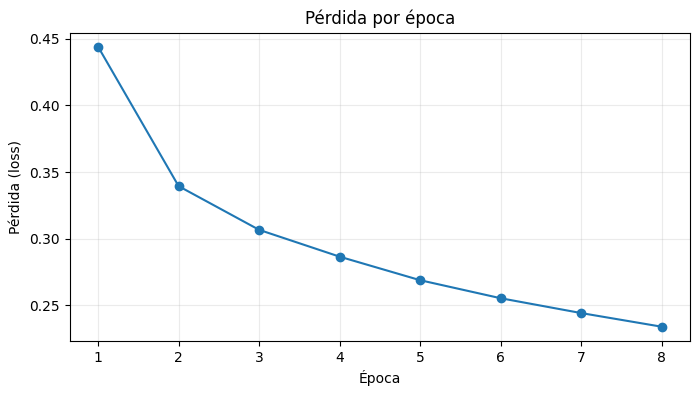


=== Resultados de prueba ===
Accuracy:        88.83%
Macro precision: 89.01%
Macro recall:    88.83%

Por clase:
Clase              Precision      Recall
T-shirt/top           82.18%      86.70%
Trouser               98.29%      97.50%
Pullover              86.60%      73.00%
Dress                 88.94%      88.50%
Coat                  74.30%      89.60%
Sandal                96.85%      95.40%
Shirt                 75.86%      68.50%
Sneaker               95.37%      94.70%
Bag                   96.92%      97.40%
Ankle boot            94.82%      97.00%


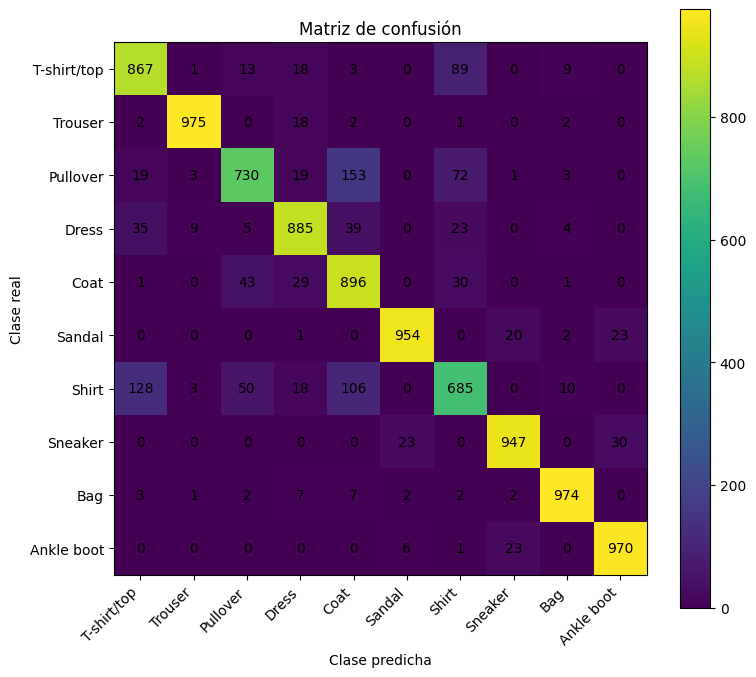

Checkpoint saved: pytorch_fashion_1_original_convolutional.pth

Training delivery model: simplified / rectangular

--- Red actual ---
Clasificación: simplified (4 clases)
Tipo: rectangular
Arquitectura: 784 -> [256, 256] -> 4
Épocas acumuladas: 0
Optimizador: Adam
Learning rate: 0.001
Weight decay: 0.0001
Batch normalization: sí
Dropout: 0.1
Early stopping: no
Epoch 1 - train_loss=0.11883
Epoch 2 - train_loss=0.08196
Epoch 3 - train_loss=0.07125
Epoch 4 - train_loss=0.06553
Epoch 5 - train_loss=0.06134
Epoch 6 - train_loss=0.05581


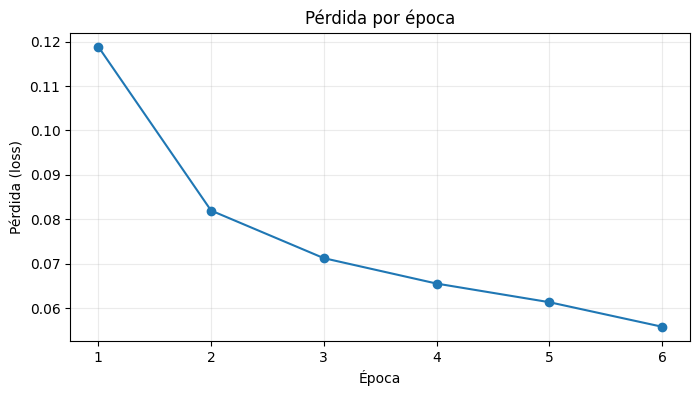


=== Resultados de prueba ===
Accuracy:        97.44%
Macro precision: 97.29%
Macro recall:    97.21%

Por clase:
Clase              Precision      Recall
Top                   97.33%      96.75%
Bottom                94.23%      95.45%
Footwear              99.54%      99.93%
Bag                   98.07%      96.70%


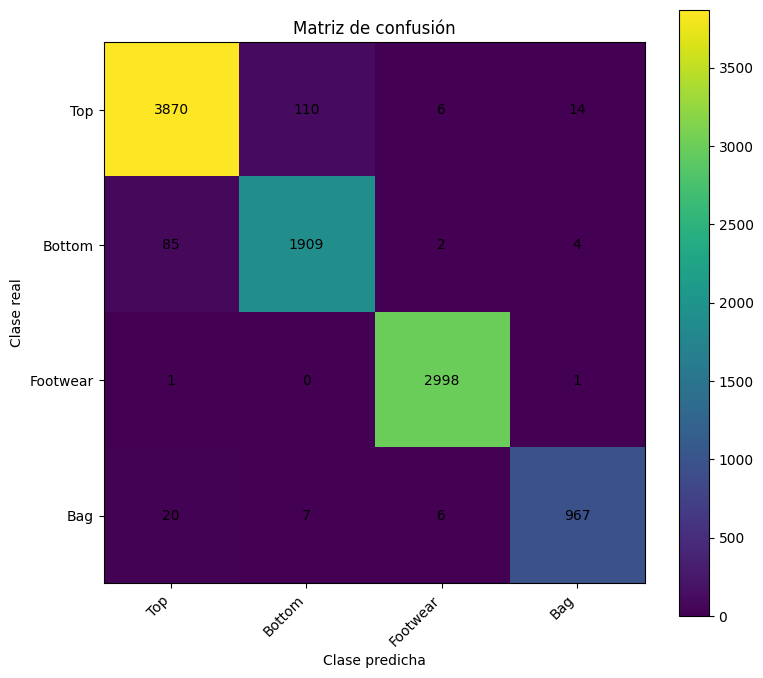

Checkpoint saved: pytorch_fashion_1_simplified_rectangular.pth

Training delivery model: simplified / convolutional

--- Red actual ---
Clasificación: simplified (4 clases)
Tipo: convolutional
Arquitectura: 784 -> [524, 264] -> 4
Épocas acumuladas: 0
Optimizador: Adam
Learning rate: 0.001
Weight decay: 0.0001
Batch normalization: sí
Dropout: 0.1
Early stopping: no
Epoch 1 - train_loss=0.11437
Epoch 2 - train_loss=0.08249
Epoch 3 - train_loss=0.07144
Epoch 4 - train_loss=0.06675
Epoch 5 - train_loss=0.06215
Epoch 6 - train_loss=0.05910


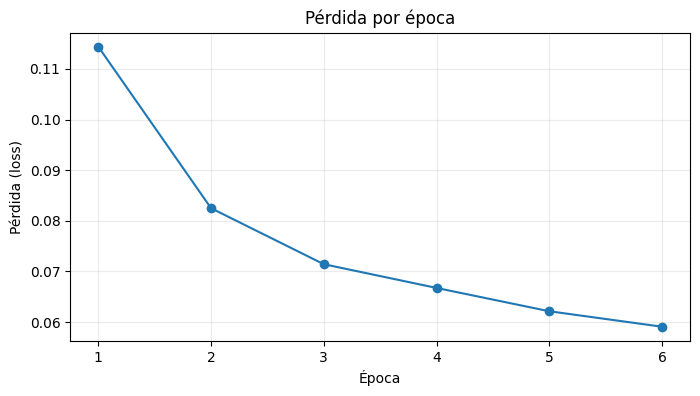


=== Resultados de prueba ===
Accuracy:        97.26%
Macro precision: 97.42%
Macro recall:    96.66%

Por clase:
Clase              Precision      Recall
Top                   95.54%      98.10%
Bottom                97.04%      91.85%
Footwear              99.70%      99.90%
Bag                   97.38%      96.80%


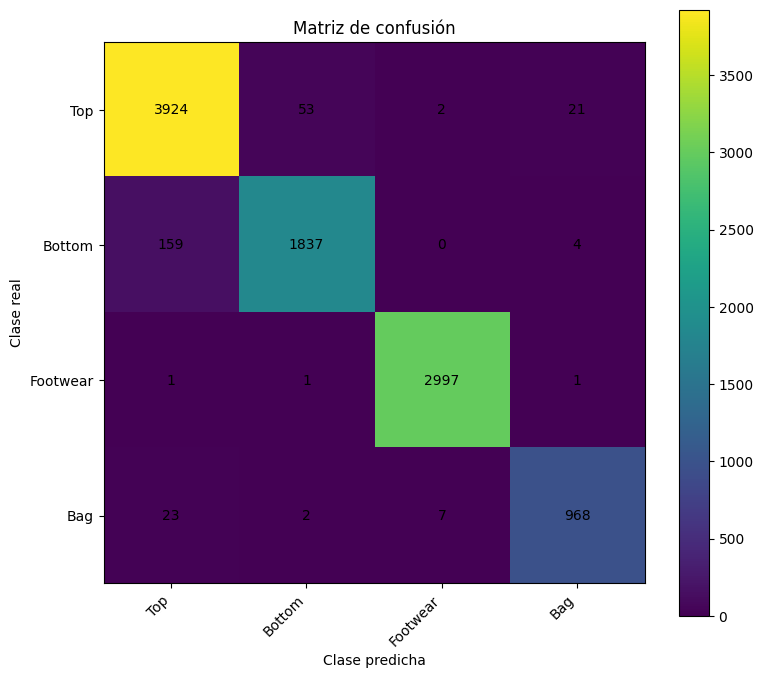

Checkpoint saved: pytorch_fashion_1_simplified_convolutional.pth

=== Resumen de las cuatro redes ===
pytorch_fashion_1_original_rectangular.pth: accuracy=87.23%
pytorch_fashion_1_original_convolutional.pth: accuracy=88.83%
pytorch_fashion_1_simplified_rectangular.pth: accuracy=97.44%
pytorch_fashion_1_simplified_convolutional.pth: accuracy=97.26%

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4) Probar red actual
5) Guardar red actual
6) Configurar entrenamiento
7) Generar las 4 redes de entrega
8) Mostrar red actual
9) Salir
Checkpoint saved: pytorch_fashion_1_original_rectangular.pth

TAREA 3 — PYTORCH / FASHION MNIST
1) Crear nueva red
2) Cargar red desde archivo
3) Entrenar red actual
4)

In [6]:
def main():
    """Main interactive loop required by the assignment."""
    current_network = None
    unsaved_training = False

    while True:
        print("\n" + "=" * 54)
        print("TAREA 3 — PYTORCH / FASHION MNIST")
        print("=" * 54)
        print("1) Crear nueva red")
        print("2) Cargar red desde archivo")
        print("3) Entrenar red actual")
        print("4) Probar red actual")
        print("5) Guardar red actual")
        print("6) Configurar entrenamiento")
        print("7) Generar las 4 redes de entrega")
        print("8) Mostrar red actual")
        print("9) Salir")

        choice = input("Opción: ").strip()

        try:
            if choice == "1":
                if current_network is not None and unsaved_training:
                    if not ask_yes_no(
                        "Hay entrenamiento sin guardar. ¿Crear otra red de todos modos?",
                        default=False,
                    ):
                        continue

                current_network = configure_new_network()
                unsaved_training = False

            elif choice == "2":
                if current_network is not None and unsaved_training:
                    if not ask_yes_no(
                        "Hay entrenamiento sin guardar. ¿Cargar otra red de todos modos?",
                        default=False,
                    ):
                        continue

                path = input("Ruta del archivo .pth: ").strip()
                current_network = load_network(path)
                unsaved_training = False
                print("Red cargada correctamente.")
                describe_network(current_network)

            elif choice == "3":
                if current_network is None:
                    print("Primero crea o carga una red.")
                    continue

                epochs = ask_integer(
                    "Número de épocas adicionales [5]: ",
                    default=5,
                    minimum=1,
                )

                train_network(current_network, epochs)
                unsaved_training = True

            elif choice == "4":
                if current_network is None:
                    print("Primero crea o carga una red.")
                    continue

                evaluate_network(current_network, show_plot=True)

            elif choice == "5":
                if current_network is None:
                    print("Primero crea o carga una red.")
                    continue

                suggested = default_checkpoint_name(current_network)
                raw_path = input(f"Archivo [{suggested}]: ").strip()
                save_network(current_network, raw_path or suggested)
                unsaved_training = False

            elif choice == "6":
                if current_network is None:
                    print("Primero crea o carga una red.")
                    continue

                configure_training_options(current_network)

            elif choice == "7":
                print(
                    "\nEsta opción entrenará cuatro redes completas y puede tardar "
                    "dependiendo de tu computadora."
                )

                if ask_yes_no("¿Continuar?", default=False):
                    train_and_save_delivery_models()

            elif choice == "8":
                if current_network is None:
                    print("No hay una red activa.")
                else:
                    describe_network(current_network)

            elif choice == "9":
                if unsaved_training:
                    if not ask_yes_no(
                        "Hay entrenamiento sin guardar. ¿Salir de todos modos?",
                        default=False,
                    ):
                        continue

                print("Programa finalizado.")
                break

            else:
                print("Opción inválida.")

        except (ValueError, OSError, RuntimeError, KeyError, FileNotFoundError) as error:
            print(f"Error: {error}")


main()
